# Global ePSF Model — `photutils` EPSFBuilder Method

This notebook demonstrates how to build a global ePSF model for a single Roman WFI
detector using the `roman_epsf.photutils` module, which wraps `photutils.psf.EPSFBuilder`.

**Workflow:**
1. Authenticate with MAST and query L2/L4 products for a program.
2. Open the calibrated detector image (`.asdf`) and source catalog (`.parquet`).
3. Select isolated, bright, unflagged point sources with `select_stars`.
4. Build a global ePSF with `build_global_epsf`.
5. Visualise the 2D ePSF model and 1D cross-sections.
6. Save the model to a FITS file and reload it to verify the round-trip.

**Requirements:** `roman-epsf` installed (with the `com` extras from `roman-cuts`).

```
pip install -e ../  # from this notebooks/ directory
```

## 0. Imports and MAST authentication

In [1]:
%load_ext autoreload
%autoreload 2
%matplotlib inline

In [2]:
import os

import matplotlib.pyplot as plt
import numpy as np
import pandas as pd
from astropy.visualization import simple_norm
from astroquery.mast import MastMissions, Observations
from dotenv import load_dotenv

# roman-cuts data-access layer
from roman_cuts.com import query_mast_files
from roman_cuts.com.io import _open_asdf, open_parquet

# roman-epsf
from roman_epsf import build_global_epsf, load_epsf, save_epsf, select_stars

In [3]:
# Load credentials and authenticate
load_dotenv("/teams/romcom/data/jmartinez/my_crds_path.env", override=True)
token = os.environ.get("MAST_API_TOKEN", "")

mission = MastMissions(mission="roman")
if token:
    mission.login(token=token)
Observations.enable_cloud_dataset()

INFO: MAST API token accepted, welcome Jorge Martinez-Palomera [astroquery.mast.auth]
INFO: Using the S3 STScI public dataset [astroquery.mast.cloud]


## 1. Query and select an L2 image + L4 catalog pair

In [4]:
pid       = 1055
detector  = 4
filter_name = "F146"

products_l2, _ = query_mast_files(
    program_id=pid, detector=detector, filter_name=filter_name,
    mission=mission, file_type="l2",
)
products_l4, _ = query_mast_files(
    program_id=pid, detector=detector, filter_name=filter_name,
    mission=mission, file_type="l4",
)

print(f"Found {len(products_l2)} L2 images and {len(products_l4)} L4 catalogs.")

# Pick one exposure and match the catalog by filename prefix
asdf_filename = products_l2["filename"][10]
prefix = asdf_filename.replace("_cal.asdf", "")
matching = [f for f in products_l4["filename"] if prefix in str(f)]
parquet_filename = matching[0] if matching else products_l4["filename"][0]

print("Image  :", asdf_filename)
print("Catalog:", parquet_filename)

INFO: 13569 of 18928 products were duplicates. Only returning 5359 unique product(s). [astroquery.mast.utils]
INFO: To return all products, use `MastMissions.get_product_list` [astroquery.mast.missions]
INFO: 13569 of 18928 products were duplicates. Only returning 5359 unique product(s). [astroquery.mast.utils]
INFO: To return all products, use `MastMissions.get_product_list` [astroquery.mast.missions]
Found 728 L2 images and 728 L4 catalogs.
Image  : r0105501001001008010_0005_wfi04_f146_cal.asdf
Catalog: r0105501001001008010_0005_wfi04_f146_cat.parquet


## 2. Load the detector image and source catalog

In [5]:
with _open_asdf(asdf_filename, mission=mission) as af:
    data = np.asarray(af["roman"]["data"], dtype=np.float64).copy()
    dq   = np.asarray(af["roman"]["dq"]).copy() if "dq" in af["roman"] else None
    gwcs = af["roman"]["meta"]["wcs"]

print(f"Image shape: {data.shape}")

if os.path.exists(str(parquet_filename)):
    cat_df = pd.read_parquet(parquet_filename)
else:
    cat_df = open_parquet(parquet_filename, token=token)

print(f"Catalog sources: {len(cat_df)}")

Image shape: (4088, 4088)
Catalog sources: 3341


## 3. Select isolated, bright point sources

`select_stars` resolves pixel coordinates from the catalog, applies boundary,
quality-flag, flux-percentile, and isolation filters, and returns a clean
sub-catalog ready for ePSF construction.

In [6]:
cutout_size = 25  # stamp size in native pixels (odd number for EPSFBuilder)

selected = select_stars(
    cat_df,
    image_shape=data.shape,
    cutout_size=cutout_size,
    flux_percentile_range=(60, 99),   # bright but unsaturated
    min_sep_factor=1.2,               # isolation radius = 1.2 × cutout_size
    gwcs=gwcs,
)
print(f"Selected {len(selected)} stars for ePSF construction.")

Selected 305 stars for ePSF construction.


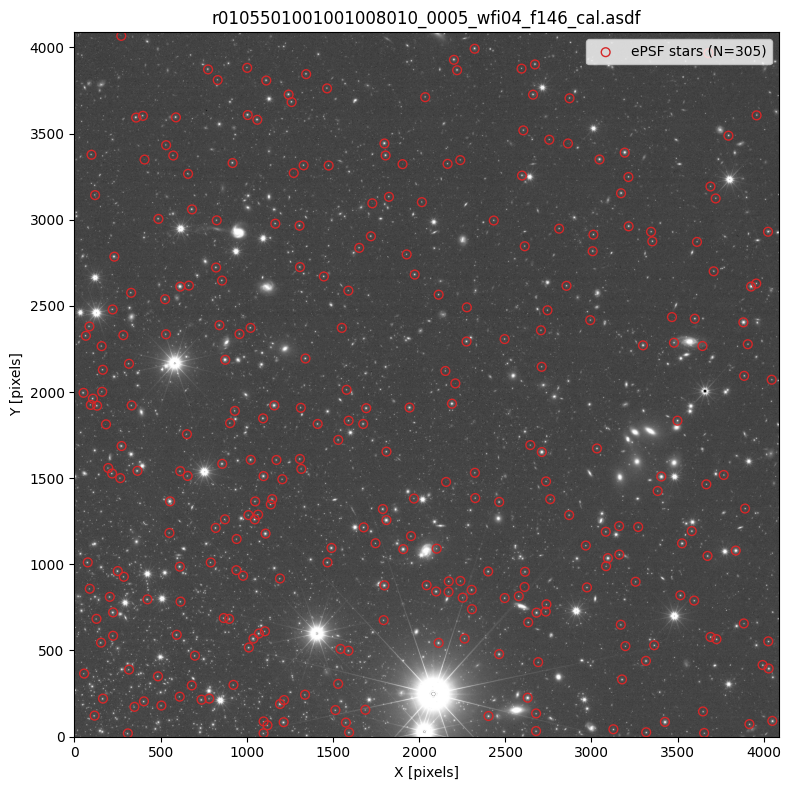

In [7]:
fig, ax = plt.subplots(figsize=(8, 8))
norm = simple_norm(data, "sqrt", percent=99.0)
ax.imshow(data, origin="lower", cmap="Greys_r", norm=norm)
ax.scatter(
    selected["x_pix"], selected["y_pix"],
    s=40, facecolors="none", edgecolors="tab:red", linewidths=1.0,
    label=f"ePSF stars (N={len(selected)})",
)
ax.set_xlabel("X [pixels]")
ax.set_ylabel("Y [pixels]")
ax.set_title(asdf_filename)
ax.legend(loc="upper right")
plt.tight_layout()
plt.show()

## 4. Build the global ePSF

`build_global_epsf` internally calls `select_stars` (here we pass the
already-selected catalog) and `extract_star_cutouts`, then runs
`EPSFBuilder`.

You can pass `background='2d'` to use a `photutils.background.Background2D`
surface instead of a scalar median, which is useful for images with structured
backgrounds.

In [8]:
epsf_model, fitted_stars, stars_df = build_global_epsf(
    data,
    selected,          # pass the already-filtered catalog
    dq=dq,
    gwcs=gwcs,
    cutout_size=cutout_size,
    oversampling=3,
    maxiters=5,
    flux_percentile_range=(0, 100),  # already filtered — keep all
    min_sep_factor=1.0,
    background="global",             # scalar sigma-clipped median subtraction
    # background="2d",               # uncomment to use Background2D instead
    # bkg2d_kwargs={"box_size": 128, "filter_size": 3},
    progress_bar=True,
)

print(f"ePSF model shape : {epsf_model.data.shape}  (oversampled)")
print(f"Stars used       : {len(fitted_stars)}")

EPSFBuilder (5 maxiters):   0%|          | 0/5 [00:00<?, ?it/s]

ePSF model shape : (75, 75)  (oversampled)
Stars used       : 303


## 5. Visualise the ePSF model

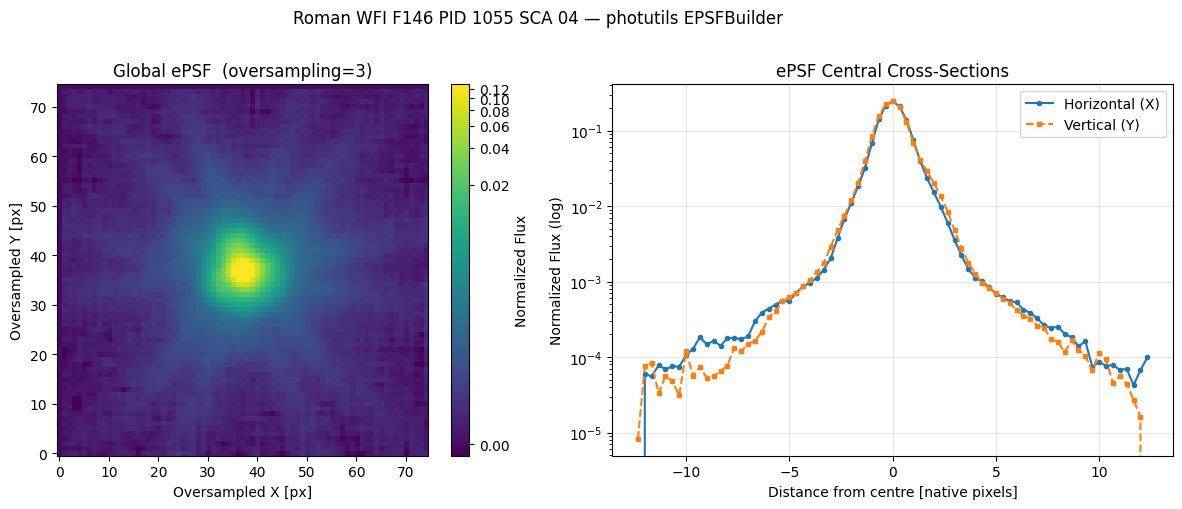

In [18]:
oversampling = epsf_model.oversampling[0]

fig, axes = plt.subplots(1, 2, figsize=(13, 5))
fig.suptitle(f"Roman WFI {filter_name} PID {pid} SCA {detector:02d} — photutils EPSFBuilder", y=1.01)

# Left: 2D ePSF image
norm_epsf = simple_norm(epsf_model.data, "log", percent=99.5)
im = axes[0].imshow(epsf_model.data, norm=norm_epsf, origin="lower", cmap="viridis")
plt.colorbar(im, ax=axes[0], fraction=0.046, pad=0.04, label="Normalized Flux")
axes[0].set_title(f"Global ePSF  (oversampling={oversampling})")
axes[0].set_xlabel("Oversampled X [px]")
axes[0].set_ylabel("Oversampled Y [px]")

# Right: 1D cross-sections through the peak
cy, cx = np.unravel_index(np.nanargmax(epsf_model.data), epsf_model.data.shape)
pix_x = (np.arange(epsf_model.data.shape[1]) - cx) / oversampling
pix_y = (np.arange(epsf_model.data.shape[0]) - cy) / oversampling

axes[1].plot(pix_x, epsf_model.data[cy, :], "o-", ms=3, label="Horizontal (X)")
axes[1].plot(pix_y, epsf_model.data[:, cx], "s--", ms=3, label="Vertical (Y)")
axes[1].set_yscale("log")
axes[1].set_xlabel("Distance from centre [native pixels]")
axes[1].set_ylabel("Normalized Flux (log)")
axes[1].set_title("ePSF Central Cross-Sections")
axes[1].legend()
axes[1].grid(True, alpha=0.3)

plt.tight_layout()
plt.show()

### 5b. Inspect a sample of the individual star cutouts used

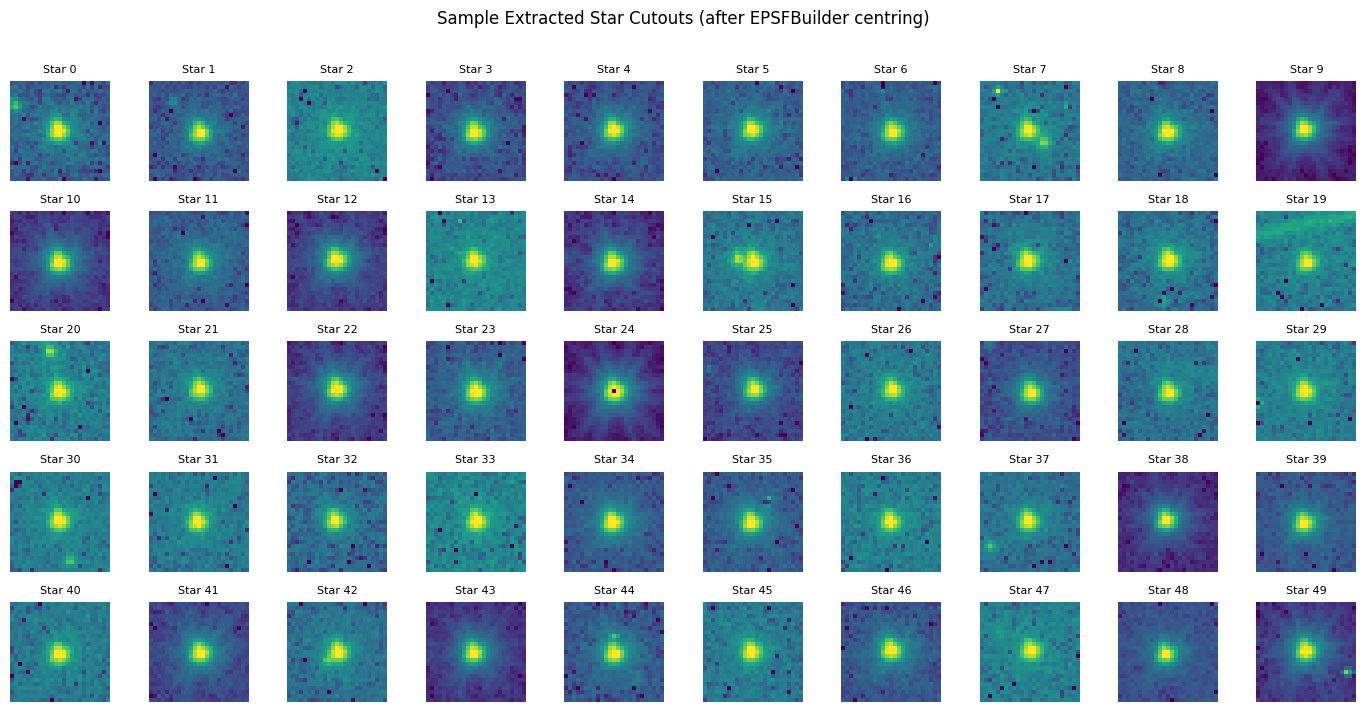

In [10]:
nrows, ncols = 5, 10
n_show = min(nrows * ncols, len(fitted_stars))

fig, axes = plt.subplots(nrows, ncols, figsize=(14, 7), squeeze=True)
axes = axes.ravel()

for i in range(nrows * ncols):
    ax = axes[i]
    if i < n_show:
        norm = simple_norm(fitted_stars[i].data, "log", percent=99.0)
        ax.imshow(fitted_stars[i].data, norm=norm, origin="lower", cmap="viridis")
        ax.set_title(f"Star {i}", fontsize=8)
    ax.axis("off")

plt.suptitle("Sample Extracted Star Cutouts (after EPSFBuilder centring)", y=1.01)
plt.tight_layout()
plt.show()

## 6. Save and reload the ePSF model

`save_epsf` writes the 2D oversampled array plus all model parameters
(`oversampling`, `origin`, flux/centroid fixed flags, etc.) to a single FITS
file.  `load_epsf` reconstructs a `photutils.psf.ImagePSF` instance that
evaluates identically to the original.

In [19]:
import os

OUT_DIR = f"/teams/romcom/data/jmartinez/data/ePSF/program_{pid}/photutils"
os.makedirs(OUT_DIR, exist_ok=True)

fits_path = f"{OUT_DIR}/roman_epsf_pid{pid}_wfi{detector:02d}_{filter_name.lower()}_global.fits"

saved = save_epsf(
    epsf_model,
    fits_path,
    extra_header={
        "INSTRUME": "WFI",
        "DETECTOR": f"WFI{detector:02d}",
        "FILTER"  : filter_name,
        "CUTSIZE" : cutout_size,
        "NSTARS"  : len(fitted_stars),
        "ASDF_REF": str(asdf_filename),
    },
)
print(f"Saved: {saved}")

Saved: /teams/romcom/data/jmartinez/data/ePSF/program_1055/photutils/roman_epsf_pid1055_wfi04_f146_global.fits


In [20]:
loaded_epsf, loaded_hdr = load_epsf(fits_path)

# Verify the round-trip is exact
yy, xx = np.mgrid[-5:6, -5:6].astype(float)
orig_eval   = epsf_model.evaluate(xx, yy, flux=1.0, x_0=0.25, y_0=-0.15)
loaded_eval = loaded_epsf.evaluate(xx, yy, flux=1.0, x_0=0.25, y_0=-0.15)

print("Data arrays match     :", np.allclose(epsf_model.data, loaded_epsf.data))
print("Evaluated stamps match:", np.allclose(orig_eval, loaded_eval))
print("\nHeader:")
for key in ["INSTRUME", "DETECTOR", "FILTER", "OVERSMPX", "NSTARS", "CUTSIZE"]:
    print(f"  {key:12s} = {loaded_hdr.get(key)}")

Data arrays match     : True
Evaluated stamps match: True

Header:
  INSTRUME     = WFI
  DETECTOR     = WFI04
  FILTER       = F146
  OVERSMPX     = 3
  NSTARS       = 303
  CUTSIZE      = 25


## 7. Evaluate the loaded ePSF at an arbitrary sub-pixel position

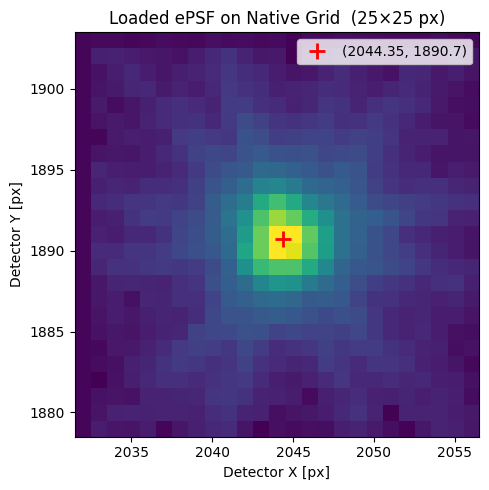

In [21]:
x0_demo, y0_demo = 2044.35, 1890.70

# Native-pixel stamp centred on the target position
half = cutout_size // 2
xc, yc = int(round(x0_demo)), int(round(y0_demo))
yy_nat, xx_nat = np.mgrid[yc - half : yc + half + 1, xc - half : xc + half + 1].astype(float)
stamp_native = loaded_epsf.evaluate(xx_nat, yy_nat, flux=1.0, x_0=x0_demo, y_0=y0_demo)

fig, ax = plt.subplots(figsize=(5, 5))
norm_s = simple_norm(stamp_native, "log", percent=99.5)
ax.imshow(
    stamp_native, norm=norm_s, origin="lower", cmap="viridis",
    extent=[xc - half - 0.5, xc + half + 0.5, yc - half - 0.5, yc + half + 0.5],
)
ax.plot(x0_demo, y0_demo, "r+", ms=12, mew=2, label=f"({x0_demo}, {y0_demo})")
ax.set_title(f"Loaded ePSF on Native Grid  ({cutout_size}×{cutout_size} px)")
ax.set_xlabel("Detector X [px]")
ax.set_ylabel("Detector Y [px]")
ax.legend()
plt.tight_layout()
plt.show()